Every field in this course, from bioinformatics to drug discovery, studies one thing: **the cell**, and the molecules inside it. Before any DNA or proteins, we need a mental picture of what a cell is, how small it is, and what goes on inside it. That picture is what this chapter builds.

:::eli5
Your body is a city of about 37 trillion tiny rooms called **cells**. Each room has a copy of the same instruction book (DNA), little machines that read the instructions and build tools (proteins), power stations (mitochondria) and walls with doors (the membrane). Different rooms read different pages of the same book, which is why a skin cell and a brain cell look so different.
:::

## What makes something alive?

Biologists don't agree on a one-line definition, but every living thing shares a few features:

| Feature | What it means | Example |
|---|---|---|
| **Made of cells** | One cell or many | A bacterium is one cell; you are about 37 trillion |
| **Metabolism** | Takes in energy and matter and transforms them | You eat sugar and burn it for energy |
| **Homeostasis** | Keeps its inside stable | Body temperature stays near 37 °C |
| **Reproduction** | Makes more of itself | Cells divide; organisms have offspring |
| **Heredity** | Passes instructions (DNA) to offspring | You inherited half your DNA from each parent |
| **Evolution** | Populations change over generations | Bacteria evolving antibiotic resistance |

**Viruses** sit on the border. They have genes and evolve, but they have no metabolism of their own and can only copy themselves inside a living cell. That is why antiviral drugs are hard to design: there is so little virus to attack that isn't also part of us.

## The levels of life

Biology is organised in levels, each built from the one below:

**atoms → molecules → macromolecules (DNA, proteins) → organelles → cells → tissues → organs → organ systems → organism → population → ecosystem**

Computational biology works at every level. Molecular dynamics simulates atoms; structural biology studies proteins; genomics reads DNA; single-cell analysis studies cells; cancer research studies tissues and patients; epidemiology studies populations.

## How big is everything?

Biology spans an enormous range of sizes, and almost all of the interesting molecular machinery is far too small to see with a normal microscope. Two units matter most:

- **micrometre (µm)** = one millionth of a metre. Cells are measured in µm.
- **nanometre (nm)** = one billionth of a metre (1000 nm = 1 µm). Molecules are measured in nm.

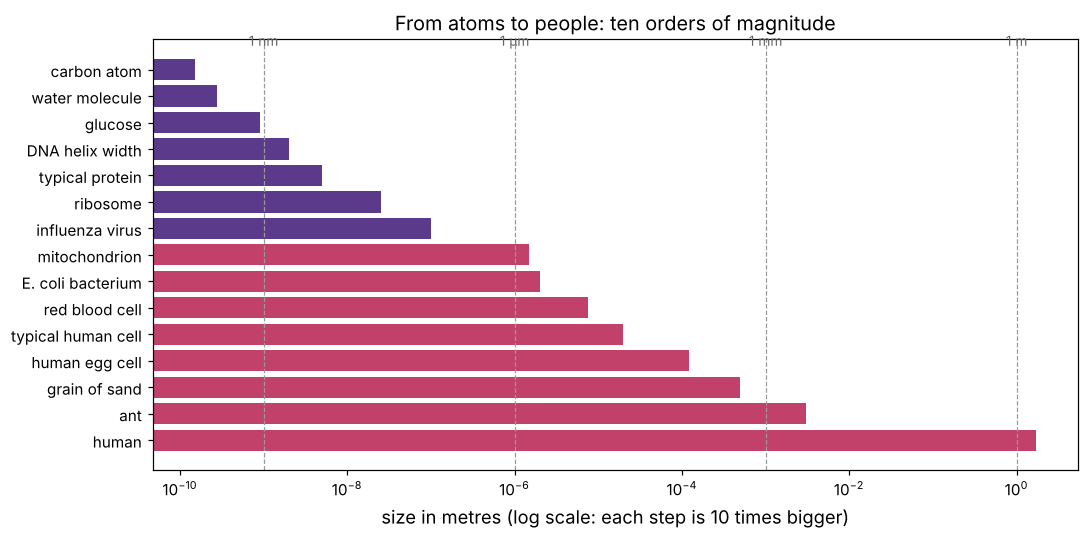

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

sizes_m = {                       # typical sizes in metres
    "carbon atom": 1.5e-10, "water molecule": 2.8e-10, "glucose": 9e-10, "DNA helix width": 2e-9,
    "typical protein": 5e-9, "ribosome": 2.5e-8, "influenza virus": 1e-7, "mitochondrion": 1.5e-6,
    "E. coli bacterium": 2e-6, "red blood cell": 7.5e-6, "typical human cell": 2e-5,
    "human egg cell": 1.2e-4, "grain of sand": 5e-4, "ant": 3e-3, "human": 1.7,
}
names, vals = list(sizes_m), np.array(list(sizes_m.values()))
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(names, vals, color=["#5b3a8c" if v < 1e-6 else "#c2416b" for v in vals])
ax.set_xscale("log"); ax.invert_yaxis()
for unit, x in [("1 nm", 1e-9), ("1 µm", 1e-6), ("1 mm", 1e-3), ("1 m", 1)]:
    ax.axvline(x, color="0.6", lw=0.8, ls="--"); ax.text(x, -0.9, unit, ha="center", fontsize=9, color="0.4")
ax.set_xlabel("size in metres (log scale: each step is 10 times bigger)")
ax.set_title("From atoms to people: ten orders of magnitude")
save_fig("scales"); plt.show()
R["orders"] = f"{np.log10(vals.max() / vals.min()):.0f}"

![Figure P1-1. Typical sizes of biological objects on a logarithmic scale. Purple items are smaller than a micrometre and invisible in an ordinary light microscope.](images/scales.png)

From a carbon atom to a person is about 10 powers of ten. Each step on that scale needs different tools: light microscopes resolve cells (down to about 0.2 µm), electron microscopes and cryo-EM resolve molecular machines, and X-ray crystallography and AlphaFold resolve individual atoms in proteins.

## Why are cells so small? A first calculation

Cells live by exchanging molecules with their surroundings through their surface: food in, waste out. Two simple geometric facts explain why cells stay small.

:::math
For a sphere of radius $r$, surface area $= 4\pi r^2$ and volume $= \tfrac43\pi r^3$, so

$$\frac{\text{surface}}{\text{volume}} = \frac{3}{r}.$$

Double the radius and each unit of volume has only half as much surface to feed it.

Inside a cell, molecules move by **diffusion**, random jiggling. The typical time to diffuse a distance $x$ is

$$t \approx \frac{x^2}{2D},$$

where $D$ is the diffusion coefficient (about $100\ \mu\text{m}^2/\text{s}$ for a small molecule like glucose in water, about $10\ \mu\text{m}^2/\text{s}$ for a protein inside a cell). Time grows with the **square** of distance: ten times further takes a hundred times longer.
:::

In [2]:
D_small, D_protein = 100.0, 10.0              # diffusion coefficients, µm²/s
for label, x in [("across a bacterium", 1), ("across a human cell", 10), ("across an egg cell", 100), ("1 mm", 1000), ("1 cm", 10_000)]:
    t_small, t_prot = x**2 / (2 * D_small), x**2 / (2 * D_protein)
    def show(t):
        return f"{t * 1000:.1f} ms" if t < 1 else f"{t:.0f} s" if t < 600 else f"{t / 3600:.1f} hours" if t < 86400 * 2 else f"{t / 86400:.0f} days"
    print(f"{label:22s} small molecule {show(t_small):>10s}   protein {show(t_prot):>10s}")
R["prot_cm_days"] = f"{(1e4)**2 / (2 * D_protein) / 86400:.0f}"

across a bacterium     small molecule     5.0 ms   protein    50.0 ms
across a human cell    small molecule   500.0 ms   protein        5 s
across an egg cell     small molecule       50 s   protein      500 s
1 mm                   small molecule  1.4 hours   protein 13.9 hours
1 cm                   small molecule     6 days   protein    58 days


Diffusion is fast over a cell (milliseconds to seconds) and hopelessly slow over centimetres: a protein would take about 58 days to drift one centimetre. That's why large organisms are made of many small cells and need blood vessels to deliver oxygen and food to within a few cell-widths of every cell. It's also why **tumours** larger than a millimetre or two must grow their own blood vessels (angiogenesis, one of the hallmarks of cancer in chapter P12).

## Two kinds of cell

| | Prokaryotes (bacteria, archaea) | Eukaryotes (animals, plants, fungi, protists) |
|---|---|---|
| Size | ~1–5 µm | ~10–100 µm |
| DNA | One circular chromosome, floating in the cell | Several linear chromosomes inside a **nucleus** |
| Internal compartments | Almost none | Many membrane-bound **organelles** |
| Example | *E. coli* in your gut | your cells, yeast |

Bacteria matter enormously in this course: they are the workhorses of biotechnology (they produce insulin and many other protein drugs), the targets of antibiotics, and the source of CRISPR.

## A tour of the animal cell

Click through the parts of a cell in the playground below, then read the summary.

::playground animations/cell_lab.html 640

| Part | Job | Why it matters later |
|---|---|---|
| **Plasma membrane** | the boundary; controls what enters and leaves | most drug targets are membrane proteins (receptors, channels) |
| **Nucleus** | stores DNA; genes are read (transcribed) here | genomics, gene regulation |
| **Ribosomes** | build proteins from RNA instructions | the central dogma (P4); antibiotics target bacterial ribosomes |
| **Endoplasmic reticulum** | makes membrane and secreted proteins, and lipids | protein folding and quality control |
| **Golgi apparatus** | modifies, sorts and ships proteins | how antibodies and hormones are secreted |
| **Mitochondria** | make ATP (energy) from sugar, fat and oxygen | cancer metabolism (P9), cell death (P7) |
| **Lysosomes** | digest and recycle | some drug delivery strategies |
| **Cytoskeleton** | shape, transport, cell division | chemotherapy drugs like paclitaxel freeze it |

:::idea
A cell is not a bag of soup. It is a crowded, organised factory: about 40% of the cytoplasm by volume is protein, and molecules are constantly being made, moved, used and destroyed. Almost every process you'll study is the result of molecules bumping into each other and sticking (or not), billions of times per second.
:::

## How many cells, and how many kinds?

In [3]:
cells = {"red blood cells": 26e12, "platelets": 1.5e12, "bone marrow cells": 0.7e12, "white blood cells": 0.05e12,
         "skin and other epithelial cells": 0.4e12, "muscle cells": 0.015e12, "neurons": 0.086e12, "fat cells": 0.05e12,
         "everything else": 8.2e12}
total = sum(cells.values())
for k, v in sorted(cells.items(), key=lambda kv: -kv[1]):
    print(f"{k:32s} {v / 1e12:6.2f} trillion  ({v / total:5.1%})")
print(f"{'total':32s} {total / 1e12:6.1f} trillion")
R["rbc_share"] = f"{cells['red blood cells'] / total:.0%}"

red blood cells                   26.00 trillion  (70.3%)
everything else                    8.20 trillion  (22.2%)
platelets                          1.50 trillion  ( 4.1%)
bone marrow cells                  0.70 trillion  ( 1.9%)
skin and other epithelial cells    0.40 trillion  ( 1.1%)
neurons                            0.09 trillion  ( 0.2%)
white blood cells                  0.05 trillion  ( 0.1%)
fat cells                          0.05 trillion  ( 0.1%)
muscle cells                       0.01 trillion  ( 0.0%)
total                              37.0 trillion


These are rounded figures from published estimates (Sender, Fuchs and Milo, 2016; Bianconi et al., 2013). About 70% of your cells are red blood cells, which are small and have no nucleus. By *mass*, most of you is muscle and fat cells. There are over 200 recognised cell types, and single-cell sequencing (chapter 7) keeps discovering more.

## The big question of this course

Every cell in your body (apart from a few) has the **same DNA**. So how does a neuron become a neuron and a liver cell a liver cell? And what goes wrong when a cell becomes cancerous? The answers run through the next twelve chapters:

1. DNA stores instructions (P3).
2. Cells copy selected instructions into RNA and build proteins from them (P4).
3. Proteins do almost all the work (P5).
4. Which genes are switched on decides what a cell is (P6).
5. Cells divide under strict control (P7), and mutations can break that control (P8, P12).

:::check
1. Roughly how many nanometres wide is a typical protein? A human cell? *(About 5 nm; about 10,000–30,000 nm.)*
2. Why does the surface-to-volume ratio limit cell size? *(Volume, which needs feeding, grows faster than surface, through which food arrives.)*
3. A molecule takes 1 second to diffuse across a cell. Roughly how long to cross a distance 10 times larger? *(About 100 seconds: time grows with distance squared.)*
:::

:::exercise
Using $t = x^2/2D$, estimate how far oxygen ($D \approx 2000\ \mu\text{m}^2/\text{s}$ in water) diffuses in 1 second. Tumour cells further than about 150 µm from a blood vessel are usually starved of oxygen (hypoxic). Is that consistent?
:::

<details><summary>Solution</summary>

In [4]:
D_o2 = 2000.0
x = np.sqrt(2 * D_o2 * 1.0)
print(f"oxygen diffuses about {x:.0f} µm in one second")

oxygen diffuses about 63 µm in one second


About 60 µm in a second. Over a few seconds it reaches roughly 100–150 µm, but cells along the way consume it. So beyond about 100–200 µm from a capillary, oxygen runs out. That is why the centres of tumours become hypoxic, which makes them resistant to radiotherapy and drives the growth of new blood vessels.

</details>